# Deterministic Domain and Grid Generators

## Table of Contents
1. [Linear Spacing (`np.linspace`)](#1-linear-spacing-np-linspace)
2. [Logarithmic Spacing (`np.logspace`)](#2-logarithmic-spacing-nplogspace)
3. [Geometric Spacing (`np.geomspace`)](#3-geometric-spacing-npgeomspace)
4. [Step-Based Range (`np.arange`)](#4-step-based-range-nparange)
5. [Coordinate Grids (`np.meshgrid`)](#5-coordinate-grids-npmeshgrid)

In [9]:
import numpy as np
import matplotlib.pyplot as plt
plt.style.use('seaborn-v0_8-whitegird' if 'seaborn-v0_8-whitegird' in plt.style.available else
'default')
plt.rcParams['figure.dpi'] = 100

### 1. Linear Spacing (`np.linspace`)

#### Mathematical Formula

The step size $h$ between consecutive elements is calculated automatically as:

$$h = \frac{b - a}{N - 1}$$

The $i$-th element in the generated array is given by:

$$x_i = a + i \cdot h \quad \text{for } i = 0, 1, 2, \dots, N - 1$$

#### Pronunciation & Symbol Guide
- **$a$**: Start of interval (scalar value).
- **$b$**: End of interval (scalar value).
- **$N$**: Total number of samples to generate.
- **$h$**: Step size / increment delta.
- **$x_i$**: The $i$-th element.

In [3]:
x_linear,step_size = np.linspace(start =0,stop =10, num = 15,retstep = True)
print("Genrated Array :",x_linear)
print(f"Calculated Step Size :{step_size:4f}")

Genrated Array : [ 0.          0.71428571  1.42857143  2.14285714  2.85714286  3.57142857
  4.28571429  5.          5.71428571  6.42857143  7.14285714  7.85714286
  8.57142857  9.28571429 10.        ]
Calculated Step Size :0.714286


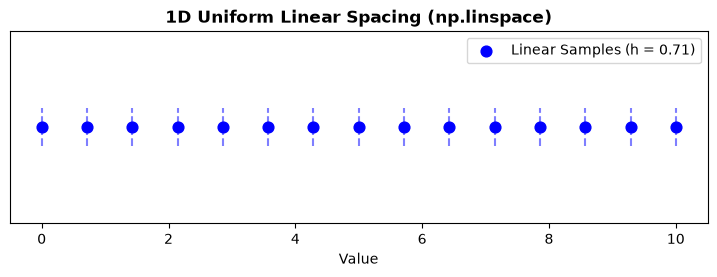

In [4]:
plt.figure(figsize = (9, 2.5))
plt.scatter(x_linear, np.zeros_like(x_linear), color = 'blue', s = 60, zorder = 3, label = f'Linear Samples (h = {step_size:.2f})')

plt.vlines(x_linear, ymin=-0.1, ymax=0.1, color = 'blue', alpha = 0.5, linestyles = '--')

plt.title('1D Uniform Linear Spacing (np.linspace)', fontsize = 12, fontweight = 'bold')
plt.xlabel('Value')
plt.yticks([])
plt.ylim(-0.5, 0.5)
plt.legend(loc = 'upper right')

## 2. Logarithmic Spacing (`np.logspace`)

- Generates numbers spaced evenly on a logarithmic scale. 
- Widely used in machine learning for defining hyperparameter search grids (e.g., learning rates $\eta$, regularization strength $\alpha$) spanning multiple orders of magnitude.

#### Mathematical Formula

Given base $k$ (default $10$), starting exponent $a$, and ending exponent $b$, the values are generated as:

$$y_i = k^{x_i} \quad \text{where } x_i = a + i \cdot \left(\frac{b - a}{N - 1}\right)$$

$$y_i = 10^{\text{linspace}(a, b, N)_i}$$

#### Pronunciation & Symbol Guide
- **$a$**: Starting power of the base (start power).
- **$b$**: Ending power of the base (stop power).
- **$k$**: Logarithmic base, typically $10$ (base $k$).
- **$y_i$**: The $i$-th element on the exponential scale ($y$ sub $i$).

[1.e-05 1.e-04 1.e-03 1.e-02 1.e-01 1.e+00 1.e+01]
Generated Hyperparameter Search Grid (Learning Rates):
Index 0: 0.000010
Index 1: 0.000100
Index 2: 0.001000
Index 3: 0.010000
Index 4: 0.100000
Index 5: 1.000000
Index 6: 10.000000



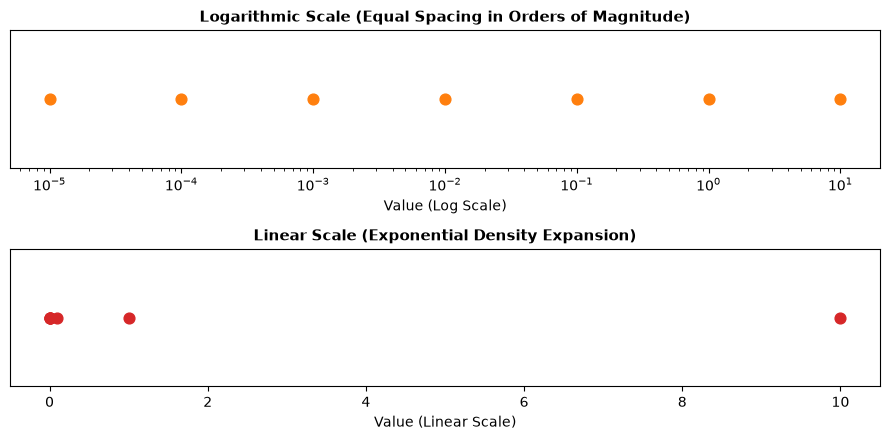

In [5]:
learning_rates = np.logspace(start=-5, stop=1, num=7, base=10.0)
print(learning_rates)
print("Generated Hyperparameter Search Grid (Learning Rates):")
for i, lr in enumerate(learning_rates):
    print(f"Index {i}: {lr:.6f}")
print()


# --- 2. GRAPHICAL VISUALIZATION ---
# Subplot layout parameters:
# - 2, 1: 2 rows, 1 column
# - figsize=(9, 4.5): Width=9 inches, Height=4.5 inches
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(9, 4.5))

# Top plot: Logarithmic scale visualization
ax1.scatter(learning_rates, np.zeros_like(learning_rates), color='#ff7f0e', s=60, zorder=3)
ax1.set_xscale('log')     # Transforms horizontal axis to logarithmic scale (10^x base scale)
ax1.set_title('Logarithmic Scale (Equal Spacing in Orders of Magnitude)', fontsize=11, fontweight='bold')
ax1.set_xlabel('Value (Log Scale)')
ax1.set_yticks([])

# Bottom plot: Standard linear scale visualization (shows exponential accumulation near zero)
ax2.scatter(learning_rates, np.zeros_like(learning_rates), color='#d62728', s=60, zorder=3)
ax2.set_title('Linear Scale (Exponential Density Expansion)', fontsize=11, fontweight='bold')
ax2.set_xlabel('Value (Linear Scale)')
ax2.set_yticks([])

plt.tight_layout()
plt.show()

## 3. Geometric Spacing (`np.geomspace`)

- Generates numbers spaced evenly on a logarithmic scale, but allows specifying the actual start and end values directly instead of specifying exponent powers. 
- Useful for geometric ratio progression sequences.

#### Mathematical Formula

For start endpoint $p > 0$ and stop endpoint $q > 0$:

$$g_i = p \cdot \left(\frac{q}{p}\right)^{\frac{i}{N - 1}} \quad \text{for } i = 0, 1, 2, \dots, N - 1$$

The constant multiplicative common ratio $r$ between successive terms is:

$$r = \left(\frac{q}{p}\right)^{\frac{1}{N - 1}}$$

#### Pronunciation & Symbol Guide
- **$p$**: Actual starting value ($p$).
- **$q$**: Actual ending value ($q$).
- **$N$**: Total number of samples to generate ($N$).
- **$g_i$**: The $i$-th element in the geometric sequence ($g$ sub $i$).
- **$r$**: Common ratio between successive terms ($r$).

=== 3. GEOMETRIC SPACING OUTPUT ===
Generated Geometric Progression Array:
[   1.            3.98107171   15.84893192   63.09573445  251.18864315
 1000.        ]
Common Multiplicative Ratio (r): 3.9811



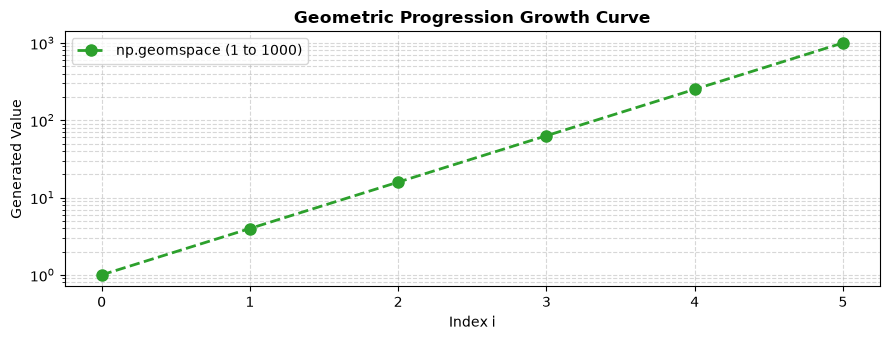

In [6]:
# --- 1. DATA GENERATION & PRINT OUTPUT ---
geom_grid = np.geomspace(start=1.0, stop=1000.0, num=6)

print("=== 3. GEOMETRIC SPACING OUTPUT ===")
print("Generated Geometric Progression Array:")
print(geom_grid)
print(f"Common Multiplicative Ratio (r): {geom_grid[1]/geom_grid[0]:.4f}\n")


# --- 2. GRAPHICAL VISUALIZATION ---
plt.figure(figsize=(9, 3.5))

# Plot formatting parameters detailed:
# - 'o--': Combined shorthand for marker type 'o' (circle) and line style '--' (dashed)
# - linewidth=2: Line thickness in points
# - markersize=8: Marker symbol size diameter in points
plt.plot(range(len(geom_grid)), geom_grid, 'o--', color='#2ca02c', linewidth=2, markersize=8, label='np.geomspace (1 to 1000)')

plt.title('Geometric Progression Growth Curve', fontsize=12, fontweight='bold')
plt.xlabel('Index i')
plt.ylabel('Generated Value')
plt.yscale('log')          # Logarithmic y-scale turns geometric curve into a straight line

# Grid parameters detailed:
# - True: Enable gridlines
# - which="both": Draw gridlines for BOTH major grid increments and minor logarithmic sub-ticks
#                 Options: 'major' (default), 'minor' (sub-ticks only), 'both' (all lines)
# - ls="--": Short for linestyle='--' (dashed)
# - alpha=0.5: Line transparency
plt.grid(True, which="both", ls="--", alpha=0.5)

plt.legend()
plt.tight_layout()
plt.show()

### 4. Step-Based Range (`np.arange`)

- Generates evenly spaced values within a half-open interval $[a, b)$ based on an explicit step size $h$. 
- Used for indexing arrays, generating discrete time steps, and creating fixed-increment integer or floating-point domain vectors.

#### Mathematical Formula

Generates sequence $z_k$ until $z_k < b$:

$$z_k = a + k \cdot h \quad \text{where } k \in \mathbb{N}_0 \text{ such that } a + k \cdot h < b$$

#### Pronunciation & Symbol Guide
- **$a$**: Start value ($a$).
- **$b$**: Upper bound limit ($b$, non-inclusive).
- **$h$**: Explicit step size / increment ($h$ or delta).
- **$k$**: Step index integer ($k$).
- **$\mathbb{N}_0$**: Non-negative integers ($\mathbb{N}$ sub zero).


In [7]:
time_steps = np.arange(start=0.0, stop=5.0, step=0.5)

print("=== 4. STEP-BASED RANGE OUTPUT ===")
print("Generated Fixed-Step Sequence:")
print(time_steps)
print(f"Total Elements: {len(time_steps)}\n")

=== 4. STEP-BASED RANGE OUTPUT ===
Generated Fixed-Step Sequence:
[0.  0.5 1.  1.5 2.  2.5 3.  3.5 4.  4.5]
Total Elements: 10



## 5. Coordinate Grids (`np.meshgrid`)

- Constructs coordinate matrices from 1D coordinate vectors. 
- Converts 1D domain axes into 2D (or $N$-D) matrices representing spatial coordinates $(X, Y)$ across a grid. Essential for evaluating multivariate mathematical surfaces $z = f(x, y)$, rendering 3D loss landscapes, and spatial grid population.

#### Mathematical Structure

Given 1D domain vectors $\mathbf{x} = [x_0, x_1, \dots, x_{M-1}]$ of length $M$ and $\mathbf{y} = [y_0, y_1, \dots, y_{N-1}]$ of length $N$:

$$\mathbf{X} = \begin{bmatrix} x_0 & x_1 & \dots & x_{M-1} \\ x_0 & x_1 & \dots & x_{M-1} \\ \vdots & \vdots & \ddots & \vdots \\ x_0 & x_1 & \dots & x_{M-1} \end{bmatrix}_{N \times M}, \quad \mathbf{Y} = \begin{bmatrix} y_0 & y_0 & \dots & y_0 \\ y_1 & y_1 & \dots & y_1 \\ \vdots & \vdots & \ddots & \vdots \\ y_{N-1} & y_{N-1} & \dots & y_{N-1} \end{bmatrix}_{N \times M}$$

#### Pronunciation & Symbol Guide
- **$\mathbf{x}$**: 1D horizontal coordinate vector of size $M$ ($\mathbf{x}$ vector).
- **$\mathbf{y}$**: 1D vertical coordinate vector of size $N$ ($\mathbf{y}$ vector).
- **$\mathbf{X}$**: 2D matrix storing $x$-coordinates for all grid points (capital $\mathbf{X}$ matrix).
- **$\mathbf{Y}$**: 2D matrix storing $y$-coordinates for all grid points (capital $\mathbf{Y}$ matrix).

=== 5. COORDINATE GRID OUTPUT ===
X Matrix Shape: (20, 20)
Y Matrix Shape: (20, 20)
Evaluated Surface Z Shape: (20, 20)
Sample X matrix slice (first 3x3 block):
 [[-2.         -1.78947368 -1.57894737]
 [-2.         -1.78947368 -1.57894737]
 [-2.         -1.78947368 -1.57894737]]
Sample Y matrix slice (first 3x3 block):
 [[-2.         -2.         -2.        ]
 [-1.78947368 -1.78947368 -1.78947368]
 [-1.57894737 -1.57894737 -1.57894737]]



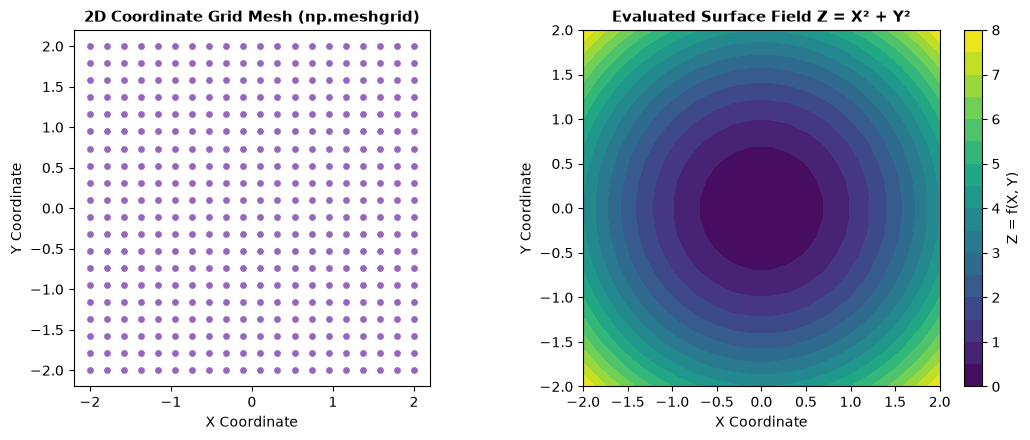

In [8]:
# --- 1. DATA GENERATION & PRINT OUTPUT ---
x_domain = np.linspace(-2, 2, 20)
y_domain = np.linspace(-2, 2, 20)

# Construct 2D coordinate matrices
X, Y = np.meshgrid(x_domain, y_domain)

# what mesh grid returns X and y?
# X contains repeated rows of x_domain, Y contains repeated columns of y_domain


# Evaluate 2D Paraboloid surface Z = X^2 + Y^2
Z = X**2 + Y**2

print("=== 5. COORDINATE GRID OUTPUT ===")
print(f"X Matrix Shape: {X.shape}")
print(f"Y Matrix Shape: {Y.shape}")
print(f"Evaluated Surface Z Shape: {Z.shape}")
print("Sample X matrix slice (first 3x3 block):\n", X[:3, :3])
print("Sample Y matrix slice (first 3x3 block):\n", Y[:3, :3])
print()


# --- 2. GRAPHICAL VISUALIZATION ---
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.5))

# Subplot 1: Grid Sampling Points
# - s=15: Small markers to show individual coordinate intersections cleanly
ax1.scatter(X, Y, color='#9467bd', s=15)
ax1.set_title('2D Coordinate Grid Mesh (np.meshgrid)', fontsize=11, fontweight='bold')
ax1.set_xlabel('X Coordinate')
ax1.set_ylabel('Y Coordinate')
ax1.set_aspect('equal')  # Ensures 1:1 aspect ratio so coordinate grid squares are not distorted

# Subplot 2: Evaluated Surface Contour Field
# Contour parameters detailed:
# - levels=15: Divide continuous surface height Z into 15 color-shaded contour bands
# - cmap='viridis': Color map palette ('viridis', 'plasma', 'coolwarm', 'magma', 'cividis')
contour = ax2.contourf(X, Y, Z, levels=15, cmap='viridis')

# Colorbar color map key attached to right side of ax2 plot
fig.colorbar(contour, ax=ax2, label='Z = f(X, Y)')
ax2.set_title('Evaluated Surface Field Z = X² + Y²', fontsize=11, fontweight='bold')
ax2.set_xlabel('X Coordinate')
ax2.set_ylabel('Y Coordinate')
ax2.set_aspect('equal')

plt.tight_layout()
plt.show()


### 3. NumPy Array Generation Methods Summary

| Function | Primary Parameter Input | Spacing Behavior | Key Real-Time Use Case |
| :--- | :--- | :--- | :--- |
| `np.linspace` | `start, stop, num` | Evenly spaced linearly over $[\text{start}, \text{stop}]$ | Sampling smooth mathematical curves & continuous time vectors |
| `np.logspace` | `start, stop, num` (as exponents: $10^{\text{start}}$ to $10^{\text{stop}}$) | Logarithmic (evenly spaced on power scale) | ML hyperparameter tuning (learning rates) & audio frequency analysis |
| `np.geomspace` | `start, stop, num` (as actual direct values) | Geometric progression (constant ratio between items) | Exponential growth models & non-uniform simulation meshes |
| `np.arange` | `start, stop, step` | Fixed step-based interval $[\text{start}, \text{stop})$ | Loop iteration, array indexing, & histogram binning |
| `np.meshgrid` | `x_array, y_array` | 2D coordinate matrices paired across grid | Evaluating 3D surfaces $Z = f(X, Y)$ for contour plots & spatial heatmaps |